# 🍹 Consumo de bebidas por cliente: comparação entre duas lojas

Projeto de análise exploratória de dados com **pandas**, **matplotlib/seaborn** e **plotly**.

## Pergunta de negócio
> Quantas bebidas, por categoria, cada loja vende **por cliente atendido** e como os perfis de consumo das duas lojas se diferenciam?

Comparar o volume absoluto de vendas seria injusto, porque as lojas atendem públicos de tamanhos diferentes. Por isso a métrica central é **bebidas por cliente** (quantidade vendida ÷ clientes atendidos).

## Roteiro
1. Carregar e validar os dados
2. Tratar e preparar as tabelas
3. Analisar o público atendido (total e por dia da semana)
4. Calcular bebidas por cliente e o mix de categorias
5. Detalhar as subcategorias de drinks e os produtos mais vendidos
6. Investigar a qualidade dos dados
7. Gerar um dashboard interativo
8. Conclusões, limitações e próximos passos

> **Sobre os dados:** as lojas foram renomeadas para *Loja A* e *Loja B* e nomes de itens que identificavam o estabelecimento foram trocados por termos genéricos.

## 1. Configuração e carregamento dos dados

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

pd.options.display.float_format = '{:,.2f}'.format
sns.set_theme(style='whitegrid', context='notebook')

CORES = {'Loja A': '#2a6f97', 'Loja B': '#e07a1f'}   # mesma cor da loja em todos os gráficos
DADOS = Path('dados')
IMG = Path('images')
IMG.mkdir(exist_ok=True)

In [2]:
clientes = pd.read_csv(DADOS / 'clientes.csv', parse_dates=['data'])
consumo = pd.read_csv(DADOS / 'consumo_bebidas.csv')

print('clientes:', clientes.shape, '| consumo:', consumo.shape)
display(clientes.head())
display(consumo.head())

clientes: (168, 5) | consumo: (177, 5)


,loja,data,dia_semana,tabela_preco,n_pessoas
0,Loja A,2025-08-01,Sexta,0,201
1,Loja A,2025-08-02,Sábado,0,266
2,Loja A,2025-08-03,Domingo,0,234
3,Loja A,2025-08-04,Segunda,0,231
4,Loja A,2025-08-05,Terça,0,213


,loja,categoria,subcategoria,produto,quantidade
0,Loja A,SOFT DRINKS,SOFT DRINKS,AGUA COM GAS,267
1,Loja A,SOFT DRINKS,SOFT DRINKS,AGUA SEM GAS,318
2,Loja A,SOFT DRINKS,SOFT DRINKS,COCA COLA,272
3,Loja A,SOFT DRINKS,SOFT DRINKS,COCA COLA ZERO,281
4,Loja A,SOFT DRINKS,SOFT DRINKS,GUARANA ANTARCTICA,257


### Dicionário de dados

**`clientes.csv`** — clientes atendidos por dia
| Coluna | Descrição |
|---|---|
| `loja` | Loja A ou Loja B |
| `data` | Data do atendimento |
| `dia_semana` | Dia da semana |
| `tabela_preco` | Código da tabela de preço (0 ou 1) |
| `n_pessoas` | Clientes atendidos |

**`consumo_bebidas.csv`** — total vendido no período, por produto
| Coluna | Descrição |
|---|---|
| `loja` | Loja A ou Loja B |
| `categoria` | `DRINKS` ou `SOFT DRINKS` |
| `subcategoria` | Grupo do cardápio (ex.: drinks clássicos, sakes, destilados) |
| `produto` | Nome do produto |
| `quantidade` | Unidades vendidas no período |

## 2. Validação dos dados
Antes de qualquer análise, confiro nulos, duplicatas, valores impossíveis e a consistência entre data e dia da semana.

In [3]:
ordem_dias = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
mapa_dias = dict(enumerate(ordem_dias))   # 0 = segunda ... 6 = domingo

checagens = pd.Series({
    'Valores nulos (clientes)': clientes.isna().sum().sum(),
    'Valores nulos (consumo)': consumo.isna().sum().sum(),
    'Linhas duplicadas (clientes)': clientes.duplicated().sum(),
    'Linhas duplicadas (consumo)': consumo.duplicated().sum(),
    'Quantidades negativas': (consumo['quantidade'] < 0).sum(),
    'Dia da semana divergente da data': (clientes['data'].dt.dayofweek.map(mapa_dias) != clientes['dia_semana']).sum(),
}, name='ocorrências').astype(int)
checagens.to_frame()

,ocorrências
Valores nulos (clientes),0
Valores nulos (consumo),0
Linhas duplicadas (clientes),0
Linhas duplicadas (consumo),0
Quantidades negativas,0
Dia da semana divergente da data,0


In [4]:
# Período coberto e registros por dia em cada loja
periodo = clientes.groupby('loja').agg(inicio=('data', 'min'), fim=('data', 'max'),
                                       dias=('data', 'nunique'), registros=('data', 'size'))
periodo

,inicio,fim,dias,registros
loja,,,,
Loja A,2025-08-01,2025-09-25,56,56
Loja B,2025-08-01,2025-09-25,56,112


**Leitura:** não há nulos, duplicatas, quantidades negativas nem datas inconsistentes com o dia da semana. As duas lojas cobrem o mesmo período.

Um detalhe importante: a **Loja B tem duas linhas por dia** (`tabela_preco` 0 e 1), enquanto a Loja A tem uma. Assumo que o público total do dia na Loja B é a **soma das duas linhas**. Essa é uma suposição minha sobre o significado da coluna e deve ser confirmada com quem gerou os dados.

## 3. Tratamento

In [5]:
clientes['dia_semana'] = pd.Categorical(clientes['dia_semana'], categories=ordem_dias, ordered=True)

# Público por dia: soma das tabelas de preço de cada loja
publico_dia = (clientes
               .groupby(['loja', 'data', 'dia_semana'], observed=True, as_index=False)['n_pessoas']
               .sum())

# Total de clientes de cada loja no período (denominador da métrica por cliente)
total_pessoas = clientes.groupby('loja')['n_pessoas'].sum()
total_pessoas.to_frame('clientes_atendidos')

,clientes_atendidos
loja,
Loja A,13088
Loja B,26563


## 4. Público atendido

In [6]:
resumo_publico = publico_dia.groupby('loja')['n_pessoas'].agg(
    total='sum', media_por_dia='mean', minimo='min', maximo='max')
resumo_publico

,total,media_por_dia,minimo,maximo
loja,,,,
Loja A,13088,233.71,200,269
Loja B,26563,474.34,409,528


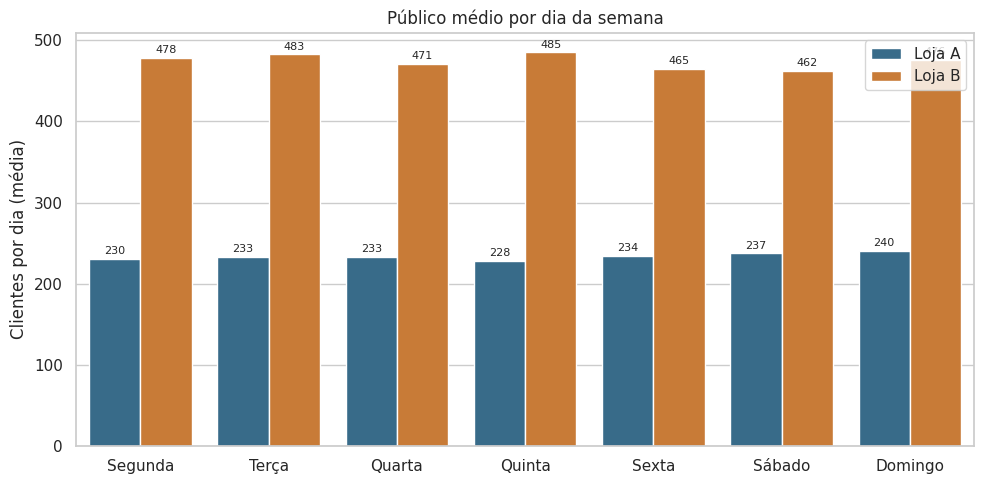

In [7]:
por_dia = (publico_dia
           .groupby(['dia_semana', 'loja'], observed=True)['n_pessoas']
           .mean().reset_index())

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=por_dia, x='dia_semana', y='n_pessoas', hue='loja', palette=CORES, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.0f', fontsize=8, padding=2)
ax.set(title='Público médio por dia da semana', xlabel='', ylabel='Clientes por dia (média)')
ax.legend(title='')
fig.tight_layout()
fig.savefig(IMG / '01_publico_dia_semana.png', dpi=150)
plt.show()

**Leitura:** a Loja B atende cerca de **2,0x** o público da Loja A por dia (474 contra 234 clientes, em média). Em ambas, o público é muito estável ao longo da semana: a diferença entre o melhor e o pior dia é de **4,9%** na Loja A e **4,8%** na Loja B.

## 5. Bebidas por cliente
Métrica central: unidades vendidas ÷ clientes atendidos, por loja e categoria.

In [8]:
qtd = consumo.groupby(['loja', 'categoria'])['quantidade'].sum().unstack('categoria')
por_cliente = qtd.div(total_pessoas, axis=0)

display(qtd)
display(por_cliente.round(3))

categoria,DRINKS,SOFT DRINKS
loja,,
Loja A,13428,9433
Loja B,1362,28408


categoria,DRINKS,SOFT DRINKS
loja,,
Loja A,1.03,0.72
Loja B,0.05,1.07


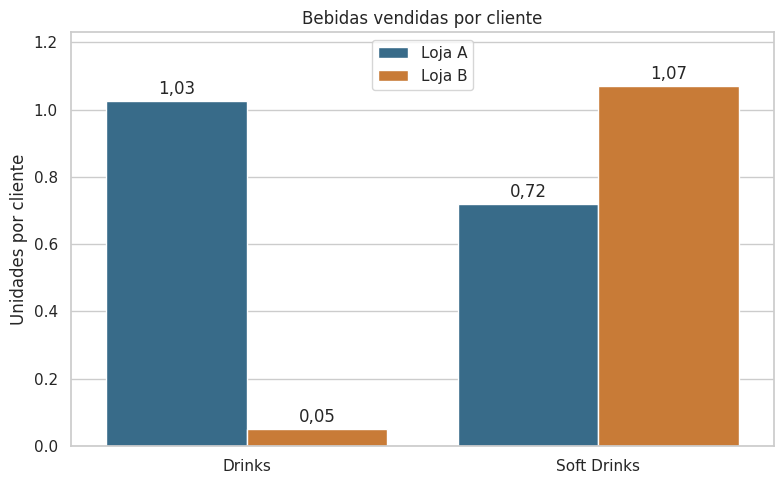

In [9]:
longo = por_cliente.reset_index().melt(id_vars='loja', var_name='categoria', value_name='por_cliente')
longo['categoria'] = longo['categoria'].str.title()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=longo, x='categoria', y='por_cliente', hue='loja', palette=CORES, ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, labels=[f'{v:.2f}'.replace('.', ',') for v in cont.datavalues], padding=2)
ax.set(title='Bebidas vendidas por cliente', xlabel='', ylabel='Unidades por cliente')
ax.set_ylim(0, longo['por_cliente'].max() * 1.15)
ax.legend(title='')
fig.tight_layout()
fig.savefig(IMG / '02_bebidas_por_cliente.png', dpi=150)
plt.show()

**Leitura:** a diferença é grande. A Loja A vende **1,03 drinks por cliente** contra **0,05** da Loja B, ou seja, cerca de **20x mais**. Em soft drinks acontece o contrário: **1,07** na Loja B contra **0,72** na Loja A (**1,5x**).

### Mix de categorias
Da venda total de bebidas de cada loja, quanto vem de cada categoria?

In [10]:
mix = qtd.div(qtd.sum(axis=1), axis=0) * 100
mix.round(1)

categoria,DRINKS,SOFT DRINKS
loja,,
Loja A,58.70,41.30
Loja B,4.60,95.40


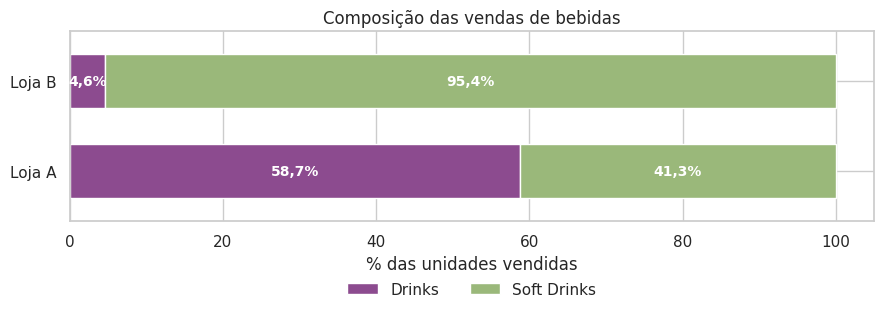

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))
mix.rename(columns=str.title).plot.barh(stacked=True, ax=ax, color=['#8c4b8f', '#9ab87a'], width=0.6)
for cont in ax.containers:
    ax.bar_label(cont, labels=[f'{v:.1f}%'.replace('.', ',') for v in cont.datavalues],
                 label_type='center', color='white', fontsize=10, fontweight='bold')
ax.set(title='Composição das vendas de bebidas', xlabel='% das unidades vendidas', ylabel='')
ax.legend(title='', loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(IMG / '03_mix_categorias.png', dpi=150, bbox_inches='tight')
plt.show()

**Leitura:** na Loja A, drinks são **58,7%** das bebidas vendidas. Na Loja B, só **4,6%**: quase tudo é soft drink.

## 6. Subcategorias de drinks
O que explica a diferença? Abro a categoria DRINKS em subcategorias, sempre por cliente.

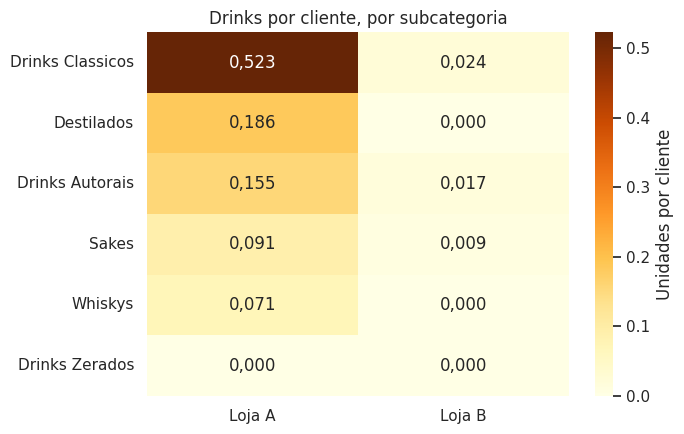

In [12]:
sub = (consumo[consumo['categoria'] == 'DRINKS']
       .groupby(['subcategoria', 'loja'])['quantidade'].sum()
       .unstack('loja').fillna(0)
       .div(total_pessoas, axis=1))
sub.index = sub.index.str.title()
sub = sub.sort_values('Loja A', ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(sub, annot=sub.map(lambda v: f'{v:.3f}'.replace('.', ',')), fmt='', cmap='YlOrBr', cbar_kws={'label': 'Unidades por cliente'}, ax=ax)
ax.set(title='Drinks por cliente, por subcategoria', xlabel='', ylabel='')
fig.tight_layout()
fig.savefig(IMG / '04_subcategorias_drinks.png', dpi=150)
plt.show()

**Leitura:** a diferença aparece em **todas as subcategorias com álcool**, não só em uma (a exceção é *Drinks Zerados*, com apenas 9 unidades na Loja B e nenhuma na Loja A). Na Loja A, os drinks clássicos chegam a **0,52 por cliente** e os destilados a **0,19**. Na Loja B, nenhuma subcategoria chega a **0,03**.

## 7. Produtos mais vendidos
Top 5 de cada loja e categoria.

In [13]:
top5 = (consumo
        .groupby(['loja', 'categoria', 'produto'])['quantidade'].sum()
        .sort_values(ascending=False)
        .groupby(level=['loja', 'categoria']).head(5)   # 5 por loja E categoria
        .sort_index())
top5.to_frame('quantidade')

quantidade
loja   categoria   produto                                            
Loja A DRINKS      CARAJILLO 43                                    345
                   COSMOPOLITAN                                    349
                   HAKUSHIKA HONJOSO SHU TRADICIONAL 720ML         350
                   JIM BEAM                                        346
                   MARGARITA                                       344
       SOFT DRINKS CAFE DESCAFEINADO                               349
                   MATE ESPECIAL                                   681
                   MATE MULE                                       333
                   SCHWEPPES CITRUS                                595
                   SPRITE LEMON FRESH                             1153
Loja B DRINKS      APEROL SPRITZ                                   134
                   CAIPIRINHA                                       77
                   MOSCOW MULE                                      94
                   SAKE DA CASA TACA                               122
                   TANGEBEER                                       111
       SOFT DRINKS AGUA COM GAS                                   3799
                   AGUA DA CASA                                   2334
                   AGUA SEM GAS                                   2710
                   COCA COLA                                      2053
                   COCA COLA ZERO                                 7551

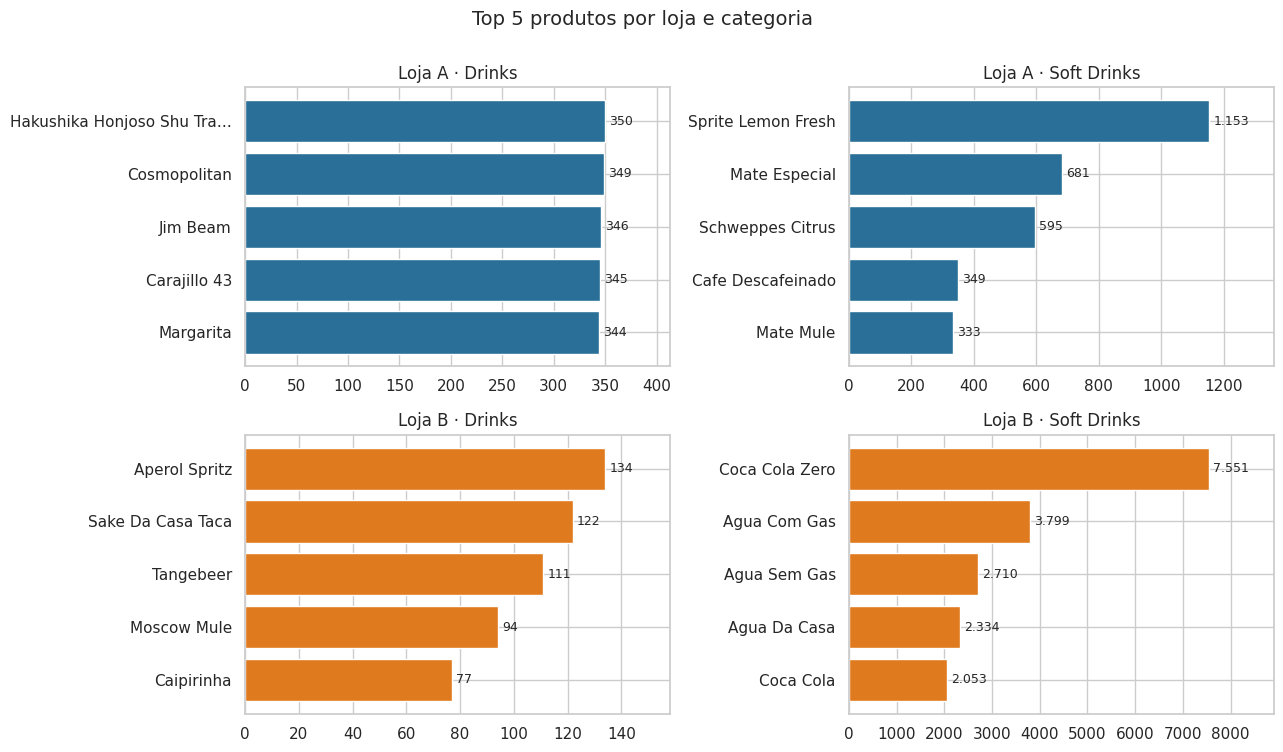

In [14]:
combinacoes = [(l, c) for l in ['Loja A', 'Loja B'] for c in ['DRINKS', 'SOFT DRINKS']]

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for ax, (loja, cat) in zip(axes.flat, combinacoes):
    d = top5.loc[(loja, cat)].sort_values()
    rotulos = [p.title() if len(p) <= 26 else p.title()[:25] + '…' for p in d.index]
    ax.barh(rotulos, d.values, color=CORES[loja])
    ax.bar_label(ax.containers[0], labels=[f'{v:,.0f}'.replace(',', '.') for v in d.values], padding=3, fontsize=9)
    ax.set_xlim(0, d.max() * 1.18)
    ax.set_title(f'{loja} · {cat.title()}')
fig.suptitle('Top 5 produtos por loja e categoria', fontsize=14, y=1.0)
fig.tight_layout()
fig.savefig(IMG / '05_top5_produtos.png', dpi=150)
plt.show()

## 8. Qualidade dos dados: uma estranheza

In [15]:
resumo_qtd = consumo.groupby('loja')['quantidade'].describe(percentiles=[.25, .5, .75, .9])
display(resumo_qtd)

a = consumo.loc[consumo['loja'] == 'Loja A', 'quantidade']
faixa = a.between(300, 350)
print(f'Loja A: {faixa.sum()} de {len(a)} produtos ({faixa.mean():.0%}) venderam entre 300 e 350 unidades.')

,count,mean,std,min,25%,50%,75%,90%,max
loja,,,,,,,,,
Loja A,92.00,248.49,165.94,1.00,211.25,279.00,324.25,344.00,"1,153.00"
Loja B,85.00,350.24,"1,017.07",1.00,5.00,26.00,134.00,"1,067.00","7,551.00"


Loja A: 33 de 92 produtos (36%) venderam entre 300 e 350 unidades.


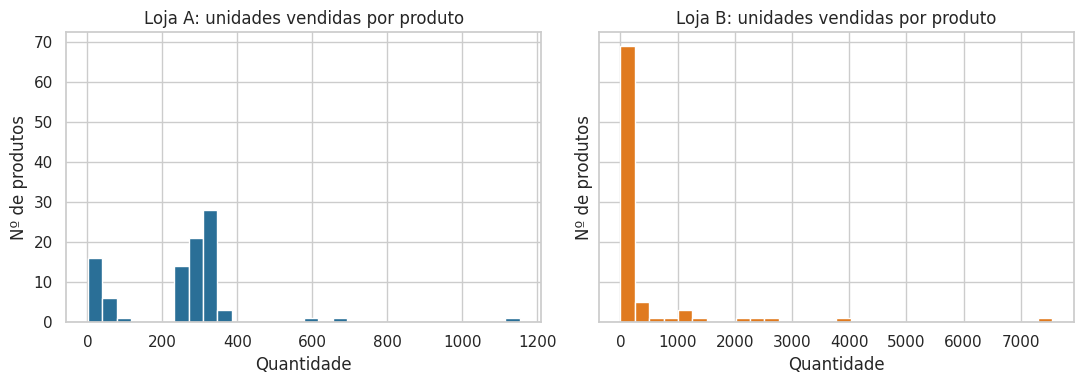

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (loja, g) in zip(axes, consumo.groupby('loja')):
    ax.hist(g['quantidade'], bins=30, color=CORES[loja])
    ax.set(title=f'{loja}: unidades vendidas por produto', xlabel='Quantidade', ylabel='Nº de produtos')
fig.tight_layout()
fig.savefig(IMG / '06_distribuicao_quantidades.png', dpi=150)
plt.show()

**Leitura:** na Loja A, **33 de 92 produtos (36%)** venderam entre 300 e 350 unidades, uma concentração incomum para vendas reais, em que normalmente poucos itens vendem muito e a maioria vende pouco (o que se vê na Loja B). Isso pode indicar um teto de registro, agrupamento de dados ou ajuste nos valores. **Antes de tirar conclusões definitivas sobre a Loja A, essa característica precisa ser confirmada na origem dos dados.**

## 9. Dashboard interativo
Gero uma página HTML com gráficos interativos (passe o mouse para ver valores; use o menu para trocar loja e categoria). Para abrir, basta clicar no arquivo `dashboard_interativo.html`.

In [17]:
# 9.1 Público por dia da semana
fig1 = go.Figure()
for loja in ['Loja A', 'Loja B']:
    d = por_dia[por_dia['loja'] == loja]
    fig1.add_trace(go.Scatter(x=d['dia_semana'].astype(str), y=d['n_pessoas'].round(1), name=loja,
                              mode='lines+markers', line=dict(color=CORES[loja], width=3),
                              hovertemplate='%{x}<br>%{y:.0f} clientes<extra>' + loja + '</extra>'))
fig1.update_layout(title='Público médio por dia da semana', yaxis=dict(title='Clientes por dia', rangemode='tozero'),
                   template='plotly_white', height=420)

# 9.2 Bebidas por cliente
fig2 = go.Figure()
for loja in ['Loja A', 'Loja B']:
    fig2.add_trace(go.Bar(x=['Drinks', 'Soft drinks'],
                          y=por_cliente.loc[loja, ['DRINKS', 'SOFT DRINKS']].round(3),
                          name=loja, marker_color=CORES[loja],
                          hovertemplate='%{x}<br>%{y:.2f} por cliente<extra>' + loja + '</extra>'))
fig2.update_layout(title='Bebidas vendidas por cliente', barmode='group', yaxis_title='Unidades por cliente',
                   template='plotly_white', height=420)

# 9.3 Top 10 de produtos com seletor de loja e categoria
totais = consumo.groupby(['loja', 'categoria', 'produto'], as_index=False)['quantidade'].sum()
fig3 = go.Figure()
botoes = []
for i, (loja, cat) in enumerate(combinacoes):
    d = totais[(totais['loja'] == loja) & (totais['categoria'] == cat)].nlargest(10, 'quantidade').sort_values('quantidade')
    fig3.add_trace(go.Bar(x=d['quantidade'], y=[p.title() for p in d['produto']], orientation='h',
                          marker_color=CORES[loja], visible=(i == 0),
                          hovertemplate='%{y}<br>%{x:,} unidades<extra></extra>'))
    botoes.append(dict(label=f'{loja} · {cat.title()}', method='update',
                       args=[{'visible': [j == i for j in range(len(combinacoes))]},
                             {'title': f'Top 10 produtos — {loja} · {cat.title()}'}]))
fig3.update_layout(title=f'Top 10 produtos — {combinacoes[0][0]} · {combinacoes[0][1].title()}',
                   updatemenus=[dict(buttons=botoes, direction='down', x=0, xanchor='left', y=1.18, yanchor='top')],
                   template='plotly_white', height=520, margin=dict(l=220, t=110), xaxis_title='Unidades vendidas')

# fig.show()  # descomente para ver os gráficos aqui no Jupyter
pagina = ('<html><head><meta charset="utf-8"><title>Consumo de bebidas por cliente</title>'
          '<style>body{font-family:Arial,sans-serif;max-width:1000px;margin:24px auto;padding:0 16px;color:#222}</style>'
          '</head><body><h1>Consumo de bebidas por cliente</h1>'
          '<p>Comparação entre Loja A e Loja B. Passe o mouse sobre os gráficos e use o menu do último gráfico.</p>'
          + fig1.to_html(full_html=False, include_plotlyjs='cdn')
          + fig2.to_html(full_html=False, include_plotlyjs=False)
          + fig3.to_html(full_html=False, include_plotlyjs=False)
          + '</body></html>')
Path('dashboard_interativo.html').write_text(pagina, encoding='utf-8')
print('Dashboard salvo em dashboard_interativo.html')

Dashboard salvo em dashboard_interativo.html


## 10. Resumo numérico

In [18]:
resumo = pd.DataFrame({
    'Clientes atendidos': total_pessoas,
    'Clientes por dia (média)': publico_dia.groupby('loja')['n_pessoas'].mean(),
    'Drinks por cliente': por_cliente['DRINKS'],
    'Soft drinks por cliente': por_cliente['SOFT DRINKS'],
    '% drinks no mix': mix['DRINKS'],
}).T
resumo

loja,Loja A,Loja B
Clientes atendidos,"13,088.00","26,563.00"
Clientes por dia (média),233.71,474.34
Drinks por cliente,1.03,0.05
Soft drinks por cliente,0.72,1.07
% drinks no mix,58.74,4.58


## 11. Conclusões

1. **Perfis de consumo opostos.** A Loja A vende **1,03 drinks por cliente** (59% do mix); a Loja B vende **0,05** (5% do mix), com a venda concentrada em soft drinks (1,07 por cliente).
2. **A diferença não está em um produto específico.** Todas as subcategorias de drinks com álcool (clássicos, autorais, destilados, sakes, whiskys) são muito menores na Loja B.
3. **O público é estável.** Em ambas as lojas, o dia da semana muda o público em menos de 5%, então a sazonalidade semanal não explica a diferença.
4. **Não é falta de público.** A Loja B atende cerca de 2,0x mais clientes por dia, mas vende bem menos drinks no total (1.362 contra 13.428 unidades na Loja A).

### Hipóteses para a diferença (a validar com a área de negócio)
- Perfil de público ou de ocasião de consumo diferente em cada ponto.
- Cardápio ou política de venda de bebidas alcoólicas diferente entre as lojas.
- Vendas de drinks registradas em outro canal ou cadastro na Loja B.

## 12. Limitações e próximos passos

**Limitações**
- A aba de consumo traz o **total do período** por produto, sem data. Não é possível cruzar consumo com dia da semana nem medir tendência.
- A soma das duas linhas diárias da Loja B (`tabela_preco` 0 e 1) é uma suposição.
- As categorias vêm da classificação do cadastro: *Soft drinks* inclui café e mates, e *Drinks* inclui drinks sem álcool e sakes.
- A concentração de quantidades da Loja A (seção 8) precisa ser verificada na origem.

**Próximos passos**
- Obter o consumo **por dia** para analisar tendência e sazonalidade.
- Calcular o **ticket médio** e a receita por cliente (preciso dos preços).
- Testar se a diferença entre lojas é estável em outros períodos.
- Repetir a análise para as demais categorias do cardápio (pratos, sobremesas, vinhos).